# EA3 — Comparación de datos climáticos: Medellín y Madrid (España)

**Integrantes:** Daniela Cataño Hernández · John Freddy Ocampo Ochoa · Óscar Alonso De La Pava Suárez
**Curso:** Analítica de Datos – IU Digital de Antioquia

**Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y Madrid durante el mismo periodo?

**Contenido**
1. Fuentes y descripción de las tablas
2. A. Planteamiento de la comparación
3. B. Carga y revisión de los datos
4. C. Análisis con NumPy
5. D. Gráficas comparativas
6. E. Interpretación de resultados

## 1. Fuentes y descripción de las tablas

| | Tabla 1 | Tabla 2 |
|---|---|---|
| **Ciudad** | Medellín, Colombia | Madrid, España |
| **Coordenadas solicitadas** | 6.2518° N, 75.5636° O | 40.4168° N, 3.7038° O |
| **Celda de la fuente (elevación)** | 6.22° N, 75.55° O (1.493 m) | 40.39° N, 3.68° O (666 m) |
| **Fuente** | Open-Meteo, *Historical Weather API* | Open-Meteo, *Historical Weather API* |
| **Enlace** | https://open-meteo.com/en/docs/historical-weather-api | https://open-meteo.com/en/docs/historical-weather-api |
| **Periodo** | 2024-01-01 a 2024-12-31 (año calendario completo) | 2024-01-01 a 2024-12-31 (año calendario completo) |
| **Frecuencia** | Diaria (día local, zona `America/Bogota`) | Diaria (día local, zona `Europe/Madrid`) |
| **Archivo local** | `datos/medellin.csv` | `datos/ciudad_otro_pais.csv` |
| **Fecha de descarga** | 5 de noviembre de 2026 | 5 de noviembre de 2026 |

**Columnas utilizadas** (iguales en ambas tablas):

| Columna | Variable de la fuente | Unidad |
|---|---|---|
| `fecha` | `time` | AAAA-MM-DD |
| `tmax_c` | `temperature_2m_max` – temperatura máxima diaria a 2 m | °C |
| `tmin_c` | `temperature_2m_min` – temperatura mínima diaria a 2 m | °C |
| `tmedia_c` | `temperature_2m_mean` – temperatura media diaria a 2 m | °C |
| `precip_mm` | `precipitation_sum` – precipitación total del día | mm |

**Sobre la fuente.** Open-Meteo publica, sin necesidad de registro, series diarias históricas construidas a partir del reanálisis ERA5 / ERA5-Land del Servicio de Cambio Climático de Copernicus (ECMWF). El reanálisis combina observaciones de estaciones, satélites y radiosondas con un modelo meteorológico. Por eso entrega series completas y homogéneas para cualquier punto del planeta. Su limitación es que representa una celda de rejilla de unos 9–25 km y no una estación puntual. En el valle de Aburrá, con relieve abrupto, los valores pueden diferir de los de una estación de SIATA o IDEAM.

**Comparabilidad.** Ambas tablas provienen de la misma fuente, cubren las mismas 366 fechas (2024 es bisiesto), tienen la misma frecuencia diaria y usan las mismas unidades (°C y mm). Por eso no fue necesario convertir unidades; en la sección B se verifica en el código. Madrid está en España, un país distinto de Colombia.

### Descarga de los datos
La siguiente celda descarga las dos tablas solo si no existen en la carpeta `datos/`. Así, el notebook funciona con los archivos guardados en el repositorio y también se puede reproducir desde cero. La descarga usa únicamente la librería estándar (`urllib` y `json`).

In [1]:
import json
import urllib.parse
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CARPETA_DATOS = Path("datos")
CARPETA_DATOS.mkdir(exist_ok=True)

FECHA_INICIO = "2024-01-01"
FECHA_FIN = "2024-12-31"
VARIABLES_FUENTE = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "precipitation_sum"]
NOMBRES_COLUMNAS = {"time": "fecha", "temperature_2m_max": "tmax_c", "temperature_2m_min": "tmin_c",
                    "temperature_2m_mean": "tmedia_c", "precipitation_sum": "precip_mm"}

CIUDADES = {
    "Medellín": {"lat": 6.2518, "lon": -75.5636, "zona": "America/Bogota", "archivo": CARPETA_DATOS / "medellin.csv"},
    "Madrid": {"lat": 40.4168, "lon": -3.7038, "zona": "Europe/Madrid", "archivo": CARPETA_DATOS / "ciudad_otro_pais.csv"},
}


def url_open_meteo(ciudad):
    """Construye la URL de la API histórica de Open-Meteo para una ciudad."""
    parametros = {
        "latitude": ciudad["lat"], "longitude": ciudad["lon"],
        "start_date": FECHA_INICIO, "end_date": FECHA_FIN,
        "daily": ",".join(VARIABLES_FUENTE), "timezone": ciudad["zona"],
        "temperature_unit": "celsius", "precipitation_unit": "mm",
    }
    return "https://archive-api.open-meteo.com/v1/archive?" + urllib.parse.urlencode(parametros)


def descargar_ciudad(nombre, ciudad):
    """Descarga la serie diaria y la guarda como CSV con nombres de columna en español."""
    url = url_open_meteo(ciudad)
    with urllib.request.urlopen(url, timeout=60) as respuesta:
        datos = json.load(respuesta)
    unidades = datos["daily_units"]
    tabla = pd.DataFrame(datos["daily"]).rename(columns=NOMBRES_COLUMNAS)
    tabla.to_csv(ciudad["archivo"], index=False)
    print(f"{nombre}: descargado desde {url}")
    print(f"   Unidades informadas por la fuente: {unidades}")
    print(f"   Elevación de la celda: {datos.get('elevation')} m")


for nombre, ciudad in CIUDADES.items():
    if ciudad["archivo"].exists():
        print(f"{nombre}: se usa el archivo local {ciudad['archivo']}")
    else:
        descargar_ciudad(nombre, ciudad)
    print(f"   URL de origen: {url_open_meteo(ciudad)}")

Medellín: se usa el archivo local datos/medellin.csv
   URL de origen: https://archive-api.open-meteo.com/v1/archive?latitude=6.2518&longitude=-75.5636&start_date=2024-01-01&end_date=2024-12-31&daily=temperature_2m_max%2Ctemperature_2m_min%2Ctemperature_2m_mean%2Cprecipitation_sum&timezone=America%2FBogota&temperature_unit=celsius&precipitation_unit=mm
Madrid: se usa el archivo local datos/ciudad_otro_pais.csv
   URL de origen: https://archive-api.open-meteo.com/v1/archive?latitude=40.4168&longitude=-3.7038&start_date=2024-01-01&end_date=2024-12-31&daily=temperature_2m_max%2Ctemperature_2m_min%2Ctemperature_2m_mean%2Cprecipitation_sum&timezone=Europe%2FMadrid&temperature_unit=celsius&precipitation_unit=mm


## A. Planteamiento de la comparación

**Periodo común:** del 1 de enero al 31 de diciembre de 2024 (366 días), con frecuencia diaria en ambas ciudades.

**Variables que se comparan:**
- Temperatura máxima, mínima y media diaria (°C).
- Precipitación diaria (mm).
- Amplitud térmica diaria = máxima − mínima (°C), calculada a partir de las anteriores.

**Predicción antes de calcular.** Medellín está a unos 6° de latitud norte, cerca del ecuador y a unos 1.500 m de altitud. Por eso esperamos temperaturas casi constantes durante todo el año y lluvias frecuentes, con dos temporadas más húmedas (alrededor de abril–mayo y octubre–noviembre). Madrid está a unos 40° de latitud norte, con clima mediterráneo continental. Allí esperamos una estación marcada: inviernos fríos, veranos calurosos, una diferencia de más de 15 °C entre el mes más cálido y el más frío, y un verano seco. Como posible similitud, esperamos que en los meses de transición de Madrid (finales de primavera y comienzos de otoño) sus temperaturas medias se acerquen a las de Medellín.

## B. Carga y revisión de los datos
Se leen las dos tablas desde `datos/`. Para cada una se muestran las columnas, las primeras filas, las dimensiones y las fechas inicial y final.

In [2]:
medellin = pd.read_csv(CIUDADES["Medellín"]["archivo"])
madrid = pd.read_csv(CIUDADES["Madrid"]["archivo"])

for nombre, tabla in [("Medellín", medellin), ("Madrid", madrid)]:
    print(f"===== {nombre} =====")
    print("Columnas:", list(tabla.columns))
    print("Dimensiones (filas, columnas):", tabla.shape)
    print("Fecha inicial:", tabla["fecha"].iloc[0], "| Fecha final:", tabla["fecha"].iloc[-1])
    print(tabla.head(5).to_string(index=False))
    print()

===== Medellín =====
Columnas: ['fecha', 'tmax_c', 'tmin_c', 'tmedia_c', 'precip_mm']
Dimensiones (filas, columnas): (366, 5)
Fecha inicial: 2024-01-01 | Fecha final: 2024-12-31
     fecha  tmax_c  tmin_c  tmedia_c  precip_mm
2024-01-01    26.3    15.9      20.0        1.5
2024-01-02    27.4    17.4      21.0        0.5
2024-01-03    26.7    16.9      20.7        0.0
2024-01-04    27.0    14.7      20.3        0.3
2024-01-05    26.9    16.3      20.0        0.4

===== Madrid =====
Columnas: ['fecha', 'tmax_c', 'tmin_c', 'tmedia_c', 'precip_mm']
Dimensiones (filas, columnas): (366, 5)
Fecha inicial: 2024-01-01 | Fecha final: 2024-12-31
     fecha  tmax_c  tmin_c  tmedia_c  precip_mm
2024-01-01     9.4     3.1       4.9        0.0
2024-01-02     9.2     1.7       5.7        0.1
2024-01-03    12.5     8.0      10.6        2.0
2024-01-04    10.8     7.4       9.4        9.6
2024-01-05     8.1     4.8       6.5        1.0



### Tipos de datos
Las fechas se convierten a `datetime64` y las mediciones a números decimales (`float`). Con `errors="coerce"`, cualquier texto no numérico queda como valor faltante (`NaN`) en lugar de interrumpir la ejecución.

In [3]:
for tabla in (medellin, madrid):
    tabla["fecha"] = pd.to_datetime(tabla["fecha"], errors="coerce")
    for columna in ["tmax_c", "tmin_c", "tmedia_c", "precip_mm"]:
        tabla[columna] = pd.to_numeric(tabla[columna], errors="coerce").astype("float64")

print("Tipos en Medellín:\n", medellin.dtypes, "\n", sep="")
print("Tipos en Madrid:\n", madrid.dtypes, sep="")

Tipos en Medellín:
fecha        datetime64[us]
tmax_c              float64
tmin_c              float64
tmedia_c            float64
precip_mm           float64
dtype: object

Tipos en Madrid:
fecha        datetime64[us]
tmax_c              float64
tmin_c              float64
tmedia_c            float64
precip_mm           float64
dtype: object


### Valores faltantes, fechas duplicadas y periodo común

In [4]:
for nombre, tabla in [("Medellín", medellin), ("Madrid", madrid)]:
    print(f"===== {nombre} =====")
    print("Valores faltantes por columna:")
    print(tabla.isna().sum().to_string())
    print("Fechas duplicadas:", tabla["fecha"].duplicated().sum())
    print("Fechas no válidas:", tabla["fecha"].isna().sum())
    print()

# El periodo debe ser idéntico en ambas tablas (misma fecha inicial, final y frecuencia diaria).
calendario = pd.date_range(FECHA_INICIO, FECHA_FIN, freq="D")
for nombre, tabla in [("Medellín", medellin), ("Madrid", madrid)]:
    assert tabla["fecha"].min() == calendario[0] and tabla["fecha"].max() == calendario[-1], nombre
    faltan = calendario.difference(tabla["fecha"])
    print(f"{nombre}: {len(calendario)} días esperados, {tabla['fecha'].nunique()} presentes, {len(faltan)} fechas ausentes")

print("¿Mismas fechas en ambas tablas?", medellin["fecha"].equals(madrid["fecha"]))

===== Medellín =====
Valores faltantes por columna:
fecha        0
tmax_c       0
tmin_c       0
tmedia_c     0
precip_mm    0
Fechas duplicadas: 0
Fechas no válidas: 0

===== Madrid =====
Valores faltantes por columna:
fecha        0
tmax_c       0
tmin_c       0
tmedia_c     0
precip_mm    0
Fechas duplicadas: 0
Fechas no válidas: 0

Medellín: 366 días esperados, 366 presentes, 0 fechas ausentes
Madrid: 366 días esperados, 366 presentes, 0 fechas ausentes
¿Mismas fechas en ambas tablas? True


### Tratamiento de los valores faltantes
- **No se reemplazan por cero.** En la fuente, una precipitación de 0 significa que el día no tuvo lluvia; un valor ausente (`NaN`) significa que no hay dato. Si se cambiara `NaN` por 0, se crearían días secos falsos y se reduciría la lluvia total.
- Para los cálculos por ciudad se usan las funciones de NumPy que ignoran `NaN` (`np.nanmean`, `np.nansum`, `np.nanmin`, `np.nanmax`) y se informa cuántos días válidos tiene cada cálculo.
- Para las **comparaciones día a día** solo se conservan las fechas con dato válido en **ambas** ciudades. La siguiente celda calcula cuántas observaciones quedaron disponibles.

In [5]:
# Arrays NumPy de las variables seleccionadas
fechas = medellin["fecha"].to_numpy()
meses = medellin["fecha"].dt.month.to_numpy()

tmax_med, tmin_med, tmedia_med, prec_med = (medellin[c].to_numpy() for c in ["tmax_c", "tmin_c", "tmedia_c", "precip_mm"])
tmax_mad, tmin_mad, tmedia_mad, prec_mad = (madrid[c].to_numpy() for c in ["tmax_c", "tmin_c", "tmedia_c", "precip_mm"])

# Máscara de fechas válidas en ambas tablas (para comparaciones diarias)
validos_temp = np.isfinite(tmax_med) & np.isfinite(tmax_mad) & np.isfinite(tmin_med) & np.isfinite(tmin_mad)
validos_prec = np.isfinite(prec_med) & np.isfinite(prec_mad)

print("Tipo de los arrays:", type(tmax_med).__name__, tmax_med.dtype, "| forma:", tmax_med.shape)
print(f"Días con temperatura válida en ambas ciudades: {validos_temp.sum()} de {len(fechas)}")
print(f"Días con precipitación válida en ambas ciudades: {validos_prec.sum()} de {len(fechas)}")

Tipo de los arrays: ndarray float64 | forma: (366,)
Días con temperatura válida en ambas ciudades: 366 de 366
Días con precipitación válida en ambas ciudades: 366 de 366


## C. Análisis con NumPy

### C.1 Índices y cortes: un periodo breve
Con cortes de arrays (`[inicio:fin]`) se inspeccionan los primeros 7 días de enero. Con índices booleanos se toma la semana del 1 al 7 de julio, en pleno verano de Madrid.

In [6]:
semana = slice(0, 7)   # 1 al 7 de enero
print("Primera semana de enero de 2024")
print(f"{'Fecha':12}{'Tmáx Med':>10}{'Tmáx Mad':>10}{'Lluvia Med':>12}{'Lluvia Mad':>12}")
for f, a, b, c, d in zip(fechas[semana], tmax_med[semana], tmax_mad[semana], prec_med[semana], prec_mad[semana]):
    print(f"{str(f)[:10]:12}{a:>10.1f}{b:>10.1f}{c:>12.1f}{d:>12.1f}")

julio = np.flatnonzero(meses == 7)[:7]   # índices de los primeros 7 días de julio
print("\nPrimera semana de julio de 2024 (índices", julio[0], "a", julio[-1], ")")
print("Tmáx Medellín:", tmax_med[julio])
print("Tmáx Madrid:  ", tmax_mad[julio])

Primera semana de enero de 2024
Fecha         Tmáx Med  Tmáx Mad  Lluvia Med  Lluvia Mad
2024-01-01        26.3       9.4         1.5         0.0
2024-01-02        27.4       9.2         0.5         0.1
2024-01-03        26.7      12.5         0.0         2.0
2024-01-04        27.0      10.8         0.3         9.6
2024-01-05        26.9       8.1         0.4         1.0
2024-01-06        28.4       8.2         0.0         0.0
2024-01-07        27.3       8.9         0.0         0.0

Primera semana de julio de 2024 (índices 182 a 188 )
Tmáx Medellín: [27.  25.3 24.5 22.9 21.9 26.6 28. ]
Tmáx Madrid:   [29.3 31.3 33.5 36.8 38.3 33.6 31.5]


### C.2 Máscaras booleanas: días lluviosos y días calurosos
- **Día lluvioso:** precipitación ≥ 1 mm. Es el umbral habitual de la Organización Meteorológica Mundial; evita contar como lluviosos los días con lloviznas mínimas.
- **Día caluroso:** temperatura máxima > 28 °C.

Se usan **los mismos umbrales en las dos ciudades**.

In [7]:
UMBRAL_LLUVIA_MM = 1.0
UMBRAL_CALOR_C = 28.0

lluvioso_med = prec_med >= UMBRAL_LLUVIA_MM
lluvioso_mad = prec_mad >= UMBRAL_LLUVIA_MM
caluroso_med = tmax_med > UMBRAL_CALOR_C
caluroso_mad = tmax_mad > UMBRAL_CALOR_C

print(f"Días lluviosos (≥ {UMBRAL_LLUVIA_MM} mm):   Medellín = {lluvioso_med.sum()}, Madrid = {lluvioso_mad.sum()}")
print(f"Días calurosos (> {UMBRAL_CALOR_C} °C): Medellín = {caluroso_med.sum()}, Madrid = {caluroso_mad.sum()}")

# Las máscaras también sirven para seleccionar valores
print(f"\nLluvia media en los días lluviosos: Medellín = {prec_med[lluvioso_med].mean():.1f} mm, "
      f"Madrid = {prec_mad[lluvioso_mad].mean():.1f} mm")

# Máscaras combinadas con & : días calurosos y lluviosos a la vez
print(f"Días calurosos Y lluviosos: Medellín = {(caluroso_med & lluvioso_med).sum()}, "
      f"Madrid = {(caluroso_mad & lluvioso_mad).sum()}")

# Meses en que ocurrieron los días calurosos de Madrid
meses_calor_mad, conteo = np.unique(meses[caluroso_mad], return_counts=True)
print("Días calurosos de Madrid por mes:", dict(zip(meses_calor_mad.tolist(), conteo.tolist())))

Días lluviosos (≥ 1.0 mm):   Medellín = 259, Madrid = 80
Días calurosos (> 28.0 °C): Medellín = 112, Madrid = 98

Lluvia media en los días lluviosos: Medellín = 8.3 mm, Madrid = 5.9 mm
Días calurosos Y lluviosos: Medellín = 43, Madrid = 4
Días calurosos de Madrid por mes: {4: 1, 5: 10, 6: 16, 7: 31, 8: 28, 9: 11, 10: 1}


**Interpretación de las máscaras.** Medellín tuvo 259 días lluviosos (71 % del año) frente a 80 en Madrid (22 %). Con el mismo umbral de 28 °C, Medellín sumó incluso más días calurosos (112) que Madrid (98), pero los de Madrid se concentran entre mayo y septiembre (31 en julio y 28 en agosto), mientras que en Medellín se reparten a lo largo del año. La máscara combinada muestra otra diferencia: en Medellín hubo 43 días calurosos y lluviosos a la vez; en Madrid, solo 4, porque su calor coincide con la época seca.

### C.3 Medidas descriptivas por ciudad

In [8]:
def descriptivas(tmax, tmin, tmedia, prec, lluvioso, caluroso):
    return {
        "Temperatura media anual (°C)": np.nanmean(tmedia),
        "Tmáx promedio (°C)": np.nanmean(tmax),
        "Tmín promedio (°C)": np.nanmean(tmin),
        "Temperatura máxima absoluta (°C)": np.nanmax(tmax),
        "Temperatura mínima absoluta (°C)": np.nanmin(tmin),
        "Desviación estándar de Tmedia (°C)": np.nanstd(tmedia),
        "Precipitación total (mm)": np.nansum(prec),
        "Precipitación máxima en un día (mm)": np.nanmax(prec),
        "Días lluviosos (≥ 1 mm)": lluvioso.sum(),
        "Días calurosos (> 28 °C)": caluroso.sum(),
        "Días con dato de temperatura": np.isfinite(tmedia).sum(),
        "Días con dato de precipitación": np.isfinite(prec).sum(),
    }

resumen = pd.DataFrame({
    "Medellín": descriptivas(tmax_med, tmin_med, tmedia_med, prec_med, lluvioso_med, caluroso_med),
    "Madrid": descriptivas(tmax_mad, tmin_mad, tmedia_mad, prec_mad, lluvioso_mad, caluroso_mad),
})
resumen["Diferencia (Madrid − Medellín)"] = resumen["Madrid"] - resumen["Medellín"]
resumen.round(1)

,Medellín,Madrid,Diferencia (Madrid − Medellín)
Temperatura media anual (°C),20.8,15.8,-5.0
Tmáx promedio (°C),27.2,21.7,-5.5
Tmín promedio (°C),16.6,10.2,-6.4
Temperatura máxima absoluta (°C),31.8,40.4,8.6
Temperatura mínima absoluta (°C),13.9,-2.6,-16.5
Desviación estándar de Tmedia (°C),1.0,7.9,6.9
Precipitación total (mm),2176.3,490.6,-1685.7
Precipitación máxima en un día (mm),58.4,30.4,-28.0
Días lluviosos (≥ 1 mm),259.0,80.0,-179.0
Días calurosos (> 28 °C),112.0,98.0,-14.0


**Lectura de la tabla.** Medellín fue en promedio 5,0 °C más cálida que Madrid (20,8 °C frente a 15,8 °C), pero Madrid alcanzó los extremos: 40,4 °C de máxima y −2,6 °C de mínima, frente a 31,8 °C y 13,9 °C en Medellín. La desviación estándar de la temperatura media diaria (1,0 °C frente a 7,9 °C) indica que los días de Madrid son mucho más distintos entre sí. En lluvia, Medellín acumuló 2.176 mm, unas 4,4 veces lo de Madrid (491 mm). Ninguna serie tiene datos faltantes, así que todas las medidas usan los 366 días.

### C.4 Broadcasting
El broadcasting permite operar arrays de formas distintas sin escribir ciclos:
1. Se apilan las dos ciudades en una matriz de forma `(2, 366)`. Al restarle las medias por ciudad (forma `(2, 1)`) se obtienen las **anomalías diarias**: cuánto se aleja cada día del promedio de su propia ciudad.
2. Al comparar la matriz con un escalar (`> 28`), se genera la máscara de ambas ciudades en una sola operación.
3. Una matriz mensual `(2, 12)` permite calcular la **amplitud estacional** de cada ciudad y la diferencia mes a mes.

In [9]:
tmax_2d = np.vstack([tmax_med, tmax_mad])                   # forma (2, 366)
media_por_ciudad = np.nanmean(tmax_2d, axis=1, keepdims=True)  # forma (2, 1)
anomalias = tmax_2d - media_por_ciudad                       # (2, 366) − (2, 1) → (2, 366)
print("Formas:", tmax_2d.shape, "−", media_por_ciudad.shape, "→", anomalias.shape)
print("Media de Tmáx por ciudad (°C):", media_por_ciudad.ravel().round(1))
print("Anomalía máxima (°C):  Medellín = %.1f, Madrid = %.1f" % tuple(np.nanmax(anomalias, axis=1)))
print("Anomalía mínima (°C):  Medellín = %.1f, Madrid = %.1f" % tuple(np.nanmin(anomalias, axis=1)))
print("Días a más de 5 °C de su media:", (np.abs(anomalias) > 5).sum(axis=1), "(Medellín, Madrid)")

# Escalar contra matriz: misma máscara de calor para ambas ciudades
print("Días calurosos con una sola operación:", (tmax_2d > UMBRAL_CALOR_C).sum(axis=1), "(Medellín, Madrid)")

# Ejemplo de conversión de unidades por broadcasting (°C → °F); el análisis sigue en °C
print("Tmáx promedio en °F:", (media_por_ciudad.ravel() * 9 / 5 + 32).round(1))

# Matriz mensual (2, 12): temperatura media y precipitación acumulada por mes
numero_mes = np.arange(1, 13)
mascara_mes = meses[np.newaxis, :] == numero_mes[:, np.newaxis]   # (1, 366) vs (12, 1) → (12, 366)
print("Forma de la máscara mensual:", mascara_mes.shape)

def mensual(valores, funcion):
    return np.array([funcion(valores[m]) for m in mascara_mes])

temp_mensual = np.vstack([mensual(tmedia_med, np.nanmean), mensual(tmedia_mad, np.nanmean)])
prec_mensual = np.vstack([mensual(prec_med, np.nansum), mensual(prec_mad, np.nansum)])
dias_validos_mes = np.vstack([mascara_mes.astype(int) @ np.isfinite(prec_med).astype(int), mascara_mes.astype(int) @ np.isfinite(prec_mad).astype(int)])

amplitud_estacional = temp_mensual.max(axis=1) - temp_mensual.min(axis=1)
print("Amplitud estacional (mes más cálido − mes más frío, °C):", amplitud_estacional.round(1), "(Medellín, Madrid)")
print("Diferencia mensual de temperatura (Madrid − Medellín, °C):", (temp_mensual[1] - temp_mensual[0]).round(1))
print("Días con dato de precipitación por mes:\n", dias_validos_mes)

Formas: (2, 366) − (2, 1) → (2, 366)
Media de Tmáx por ciudad (°C): [27.2 21.7]
Anomalía máxima (°C):  Medellín = 4.6, Madrid = 18.7
Anomalía mínima (°C):  Medellín = -5.3, Madrid = -14.3
Días a más de 5 °C de su media: [  1 244] (Medellín, Madrid)
Días calurosos con una sola operación: [112  98] (Medellín, Madrid)
Tmáx promedio en °F: [80.9 71.1]
Forma de la máscara mensual: (12, 366)
Amplitud estacional (mes más cálido − mes más frío, °C): [ 2.5 22.2] (Medellín, Madrid)
Diferencia mensual de temperatura (Madrid − Medellín, °C): [-14.  -12.7 -11.8  -7.1  -3.1   1.7   7.4   7.8  -1.2  -4.6  -8.5 -14.3]
Días con dato de precipitación por mes:
 [[31 29 31 30 31 30 31 31 30 31 30 31]
 [31 29 31 30 31 30 31 31 30 31 30 31]]


**Interpretación del broadcasting.** Las anomalías miden cuánto se aleja cada día del promedio de su propia ciudad, lo que permite comparar ciudades con medias diferentes. En Medellín, la máxima diaria nunca se alejó más de 5,3 °C de su media (27,2 °C) y solo 1 día superó los ±5 °C. En Madrid, las anomalías fueron de −14,3 °C a +18,7 °C, y 244 días (dos de cada tres) se alejaron más de 5 °C de su media (21,7 °C). La matriz mensual lleva esto a escala de meses: la amplitud estacional es de 2,5 °C en Medellín y de 22,2 °C en Madrid. La diferencia mensual Madrid − Medellín cambia de signo: Madrid es 14 °C más fría en enero y diciembre, y 7–8 °C más cálida en julio y agosto. La matriz de días válidos confirma que cada suma mensual se calculó con todos los días del mes.

## D. Gráficas comparativas

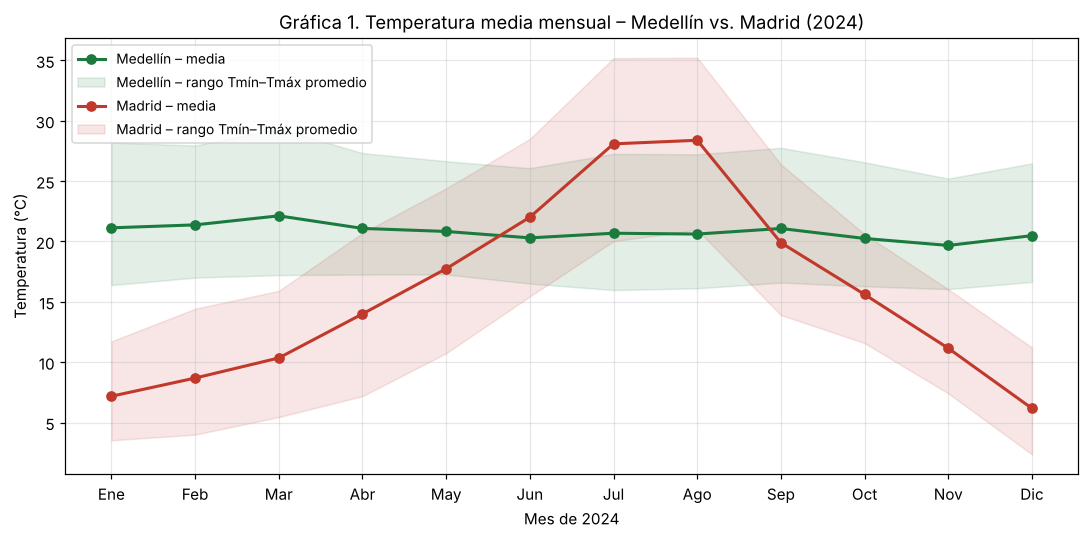

Temperatura media mensual (°C)
           Ene   Feb   Mar   Abr   May   Jun   Jul   Ago   Sep   Oct   Nov   Dic
Medellín  21.1  21.4  22.1  21.1  20.8  20.3  20.7  20.6  21.1  20.3  19.7  20.5
Madrid     7.2   8.7  10.4  14.0  17.7  22.0  28.1  28.4  19.9  15.6  11.2   6.2


In [10]:
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
COLOR_MED, COLOR_MAD = "#1b7a3e", "#c0392b"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

tmax_mensual = np.vstack([mensual(tmax_med, np.nanmean), mensual(tmax_mad, np.nanmean)])
tmin_mensual = np.vstack([mensual(tmin_med, np.nanmean), mensual(tmin_mad, np.nanmean)])

fig, ax = plt.subplots(figsize=(10, 5))
for i, (ciudad, color) in enumerate([("Medellín", COLOR_MED), ("Madrid", COLOR_MAD)]):
    ax.plot(numero_mes, temp_mensual[i], marker="o", color=color, linewidth=2, label=f"{ciudad} – media")
    ax.fill_between(numero_mes, tmin_mensual[i], tmax_mensual[i], color=color, alpha=0.12,
                    label=f"{ciudad} – rango Tmín–Tmáx promedio")
ax.set_xticks(numero_mes, nombres_meses)
ax.set_title("Gráfica 1. Temperatura media mensual – Medellín vs. Madrid (2024)")
ax.set_xlabel("Mes de 2024")
ax.set_ylabel("Temperatura (°C)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

print("Temperatura media mensual (°C)")
print(pd.DataFrame(temp_mensual.round(1), index=["Medellín", "Madrid"], columns=nombres_meses).to_string())

**Patrón observado.** La línea de Medellín es casi plana: su temperatura media mensual se movió solo entre 19,7 °C (noviembre) y 22,1 °C (marzo). La de Madrid forma una curva estacional, desde 6,2 °C en diciembre hasta 28,4 °C en agosto. Las dos líneas se cruzan dos veces, entre mayo y junio y entre agosto y septiembre; en junio (22,0 °C frente a 20,3 °C) y en septiembre (19,9 °C frente a 21,1 °C), ambas ciudades tuvieron medias parecidas. La banda sombreada muestra el rango típico entre mínima y máxima: en Madrid se desplaza con las estaciones; en Medellín se mantiene a la misma altura todo el año.

**Lo que la gráfica no permite concluir.** Son promedios mensuales: ocultan los días extremos y la variación dentro de cada mes (por ejemplo, los 40,4 °C de Madrid no aparecen). Además, muestran un solo año (2024), así que no describen el clima de largo plazo (que se define con al menos 30 años) ni permiten atribuir las diferencias a una causa concreta, como la latitud o la altitud.

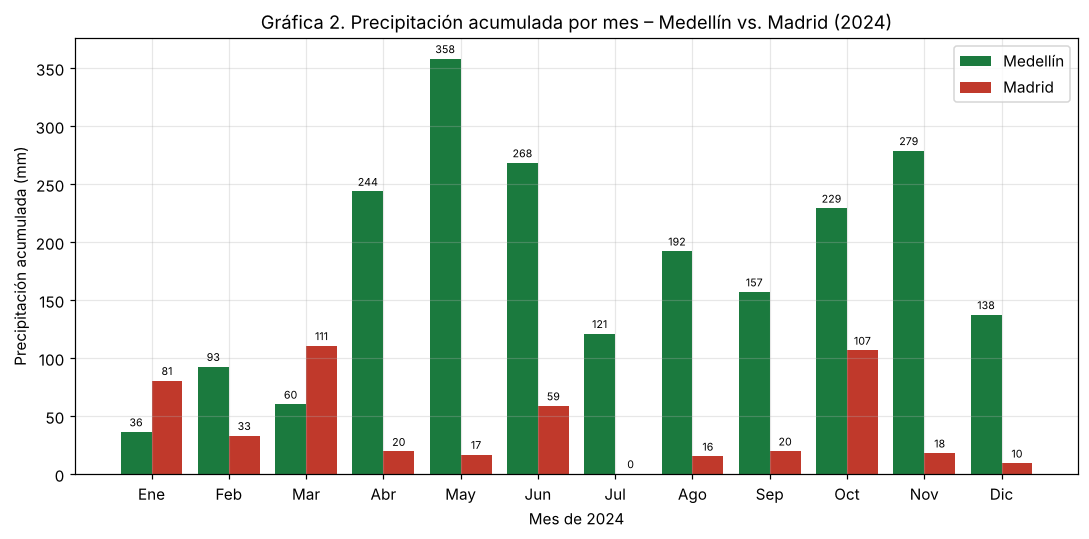

Precipitación acumulada por mes (mm)
           Ene   Feb    Mar    Abr    May    Jun    Jul    Ago    Sep    Oct    Nov    Dic
Medellín  36.0  93.0   60.0  244.0  358.0  268.0  121.0  192.0  157.0  229.0  279.0  138.0
Madrid    81.0  33.0  111.0   20.0   17.0   59.0    0.0   16.0   20.0  107.0   18.0   10.0
Mes más lluvioso:  Medellín = May | Madrid = Mar
Mes más seco:      Medellín = Ene | Madrid = Jul


In [11]:
ancho = 0.4
fig, ax = plt.subplots(figsize=(10, 5))
barras_med = ax.bar(numero_mes - ancho / 2, prec_mensual[0], ancho, color=COLOR_MED, label="Medellín")
barras_mad = ax.bar(numero_mes + ancho / 2, prec_mensual[1], ancho, color=COLOR_MAD, label="Madrid")
ax.bar_label(barras_med, fmt="%.0f", fontsize=7, padding=2)
ax.bar_label(barras_mad, fmt="%.0f", fontsize=7, padding=2)
ax.set_xticks(numero_mes, nombres_meses)
ax.set_title("Gráfica 2. Precipitación acumulada por mes – Medellín vs. Madrid (2024)")
ax.set_xlabel("Mes de 2024")
ax.set_ylabel("Precipitación acumulada (mm)")
ax.legend()
plt.tight_layout()
plt.show()

print("Precipitación acumulada por mes (mm)")
print(pd.DataFrame(prec_mensual.round(0), index=["Medellín", "Madrid"], columns=nombres_meses).to_string())
print("Mes más lluvioso:  Medellín =", nombres_meses[prec_mensual[0].argmax()], "| Madrid =", nombres_meses[prec_mensual[1].argmax()])
print("Mes más seco:      Medellín =", nombres_meses[prec_mensual[0].argmin()], "| Madrid =", nombres_meses[prec_mensual[1].argmin()])

**Patrón observado.** Medellín superó a Madrid en lluvia en 10 de los 12 meses. Sus barras dibujan dos temporadas húmedas: abril–junio (244, 358 y 268 mm; mayo fue el mes más lluvioso) y octubre–noviembre (229 y 279 mm). Enero fue su mes más seco (36 mm). Madrid tuvo poca lluvia casi todo el año, con picos en marzo (111 mm), octubre (107 mm) y enero (81 mm), y un verano seco: 0 mm en julio y 16 mm en agosto. Enero y marzo son los dos únicos meses en que Madrid llovió más que Medellín.

**Lo que la gráfica no permite concluir.** Un total mensual alto puede deberse a muchos días de lluvia moderada o a pocos aguaceros intensos (por ejemplo, un solo día de Medellín aportó 58,4 mm). Para distinguirlos hay que mirar también el número de días lluviosos (sección C.2). Al ser datos de reanálisis para una celda de rejilla, la lluvia es el valor más incierto: no reproduce bien los aguaceros locales del valle de Aburrá. Además, un año no basta para afirmar que esos meses sean siempre los más lluviosos o los más secos.

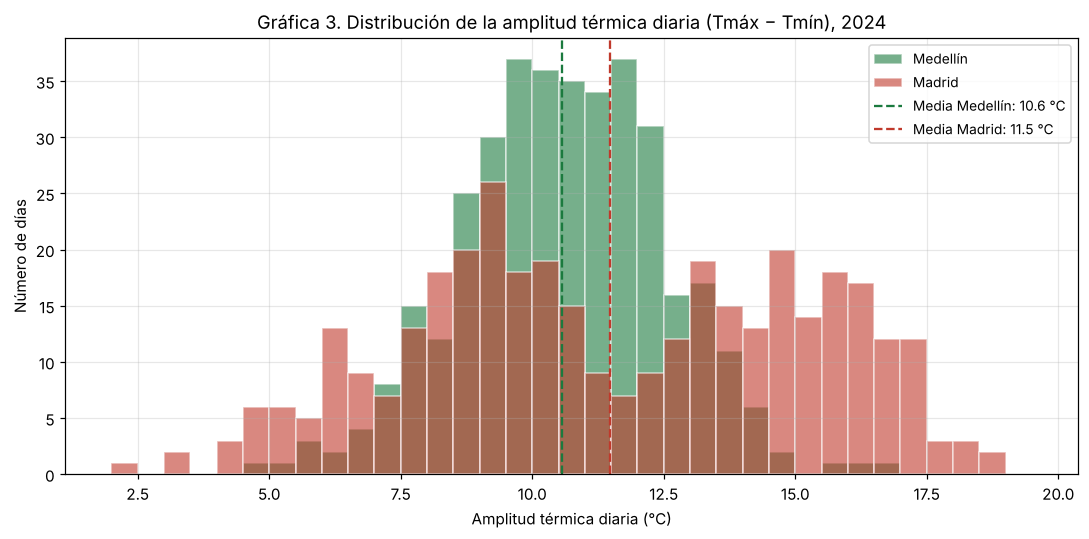

Medellín: media = 10.6 °C, percentiles 10/50/90 = 8.1 / 10.6 / 13.0 °C
Madrid: media = 11.5 °C, percentiles 10/50/90 = 6.5 / 11.1 / 16.2 °C


In [12]:
amplitud_med = tmax_med - tmin_med   # operación elemento a elemento entre arrays
amplitud_mad = tmax_mad - tmin_mad
bins = np.arange(np.floor(np.nanmin([amplitud_med, amplitud_mad])), np.ceil(np.nanmax([amplitud_med, amplitud_mad])) + 1, 0.5)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(amplitud_med[validos_temp], bins=bins, alpha=0.6, color=COLOR_MED, label="Medellín", edgecolor="white")
ax.hist(amplitud_mad[validos_temp], bins=bins, alpha=0.6, color=COLOR_MAD, label="Madrid", edgecolor="white")
ax.axvline(np.nanmean(amplitud_med), color=COLOR_MED, linestyle="--", label=f"Media Medellín: {np.nanmean(amplitud_med):.1f} °C")
ax.axvline(np.nanmean(amplitud_mad), color=COLOR_MAD, linestyle="--", label=f"Media Madrid: {np.nanmean(amplitud_mad):.1f} °C")
ax.set_title("Gráfica 3. Distribución de la amplitud térmica diaria (Tmáx − Tmín), 2024")
ax.set_xlabel("Amplitud térmica diaria (°C)")
ax.set_ylabel("Número de días")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

for ciudad, a in [("Medellín", amplitud_med), ("Madrid", amplitud_mad)]:
    p10, p50, p90 = np.nanpercentile(a, [10, 50, 90])
    print(f"{ciudad}: media = {np.nanmean(a):.1f} °C, percentiles 10/50/90 = {p10:.1f} / {p50:.1f} / {p90:.1f} °C")

**Patrón observado.** Las amplitudes térmicas medias son parecidas: 10,6 °C en Medellín y 11,5 °C en Madrid, con medianas casi iguales (10,6 y 11,1 °C). La diferencia está en la dispersión. En Medellín, el 80 % central de los días queda entre 8,1 y 13,0 °C, una distribución estrecha. En Madrid, ese mismo rango va de 6,5 a 16,2 °C: hay más días con poca diferencia entre máxima y mínima y también más días con diferencias muy grandes.

**Lo que la gráfica no permite concluir.** El histograma pierde el orden temporal: no muestra en qué época del año ocurren las amplitudes grandes. Tampoco explica por qué ocurren (nubosidad, humedad, altitud); para eso harían falta otras variables y otro tipo de análisis.

## E. Interpretación de resultados
La siguiente celda calcula, a partir de los arrays anteriores, los valores que sustentan cada hallazgo.

In [13]:
t_anual = [np.nanmean(tmedia_med), np.nanmean(tmedia_mad)]
mes_calido = [nombres_meses[i] for i in temp_mensual.argmax(axis=1)]
mes_frio = [nombres_meses[i] for i in temp_mensual.argmin(axis=1)]
total_lluvia = [np.nansum(prec_med), np.nansum(prec_mad)]
dias_lluvia = [lluvioso_med.sum(), lluvioso_mad.sum()]
meses_similares = [nombres_meses[i] for i in np.flatnonzero(np.abs(temp_mensual[1] - temp_mensual[0]) <= 2)]

print("HALLAZGO 1 – Diferencia: estacionalidad de la temperatura")
print(f"  Amplitud estacional: Medellín {amplitud_estacional[0]:.1f} °C ({mes_frio[0]} {temp_mensual[0].min():.1f} °C → "
      f"{mes_calido[0]} {temp_mensual[0].max():.1f} °C) vs. Madrid {amplitud_estacional[1]:.1f} °C "
      f"({mes_frio[1]} {temp_mensual[1].min():.1f} °C → {mes_calido[1]} {temp_mensual[1].max():.1f} °C).")
print(f"  Desviación estándar de la Tmedia diaria: Medellín {np.nanstd(tmedia_med):.1f} °C vs. Madrid {np.nanstd(tmedia_mad):.1f} °C.")
print(f"  Días calurosos (> {UMBRAL_CALOR_C:.0f} °C): Medellín {caluroso_med.sum()} vs. Madrid {caluroso_mad.sum()}.")
print()
print("HALLAZGO 2 – Similitud: meses de transición")
print(f"  Temperatura media anual: Medellín {t_anual[0]:.1f} °C vs. Madrid {t_anual[1]:.1f} °C "
      f"(diferencia {abs(t_anual[1] - t_anual[0]):.1f} °C).")
print(f"  Meses con temperatura media a 2 °C o menos de diferencia: {', '.join(meses_similares) or 'ninguno'}.")
print()
print("HALLAZGO 3 – Diferencia: cantidad y frecuencia de la lluvia")
print(f"  Precipitación total: Medellín {total_lluvia[0]:.0f} mm vs. Madrid {total_lluvia[1]:.0f} mm "
      f"(razón {total_lluvia[0] / total_lluvia[1]:.1f} veces).")
print(f"  Días lluviosos (≥ 1 mm): Medellín {dias_lluvia[0]} vs. Madrid {dias_lluvia[1]}.")
print(f"  Mes más lluvioso: Medellín {nombres_meses[prec_mensual[0].argmax()]} ({prec_mensual[0].max():.0f} mm), "
      f"Madrid {nombres_meses[prec_mensual[1].argmax()]} ({prec_mensual[1].max():.0f} mm).")
print()
print(f"Observaciones utilizadas: {validos_temp.sum()} días con temperatura válida y "
      f"{validos_prec.sum()} con precipitación válida en ambas ciudades, de {len(fechas)} posibles.")

HALLAZGO 1 – Diferencia: estacionalidad de la temperatura
  Amplitud estacional: Medellín 2.5 °C (Nov 19.7 °C → Mar 22.1 °C) vs. Madrid 22.2 °C (Dic 6.2 °C → Ago 28.4 °C).
  Desviación estándar de la Tmedia diaria: Medellín 1.0 °C vs. Madrid 7.9 °C.
  Días calurosos (> 28 °C): Medellín 112 vs. Madrid 98.

HALLAZGO 2 – Similitud: meses de transición
  Temperatura media anual: Medellín 20.8 °C vs. Madrid 15.8 °C (diferencia 5.0 °C).
  Meses con temperatura media a 2 °C o menos de diferencia: Jun, Sep.

HALLAZGO 3 – Diferencia: cantidad y frecuencia de la lluvia
  Precipitación total: Medellín 2176 mm vs. Madrid 491 mm (razón 4.4 veces).
  Días lluviosos (≥ 1 mm): Medellín 259 vs. Madrid 80.
  Mes más lluvioso: Medellín May (358 mm), Madrid Mar (111 mm).

Observaciones utilizadas: 366 días con temperatura válida y 366 con precipitación válida en ambas ciudades, de 366 posibles.


### Respuesta a la pregunta guía

**Hallazgo 1 – Diferencia: la estacionalidad de la temperatura.** Madrid tiene una estación térmica marcada y Medellín no. La amplitud estacional fue de 2,5 °C en Medellín (de 19,7 °C en noviembre a 22,1 °C en marzo) y de 22,2 °C en Madrid (de 6,2 °C en diciembre a 28,4 °C en agosto). La desviación estándar de la temperatura media diaria (1,0 °C frente a 7,9 °C) y la Gráfica 1 lo confirman. Por eso, aunque con el umbral de 28 °C ambas ciudades tuvieron una cantidad parecida de días calurosos (112 en Medellín y 98 en Madrid), en Madrid el 76 % de ellos se concentró en junio, julio y agosto (75 de 98), mientras que en Medellín se repartieron durante el año. Esto coincide con la predicción inicial.

**Hallazgo 2 – Similitud: temperaturas parecidas en los meses de transición y amplitud diaria similar.** Aunque Madrid fue 5,0 °C más fría en el promedio anual, en junio y septiembre las medias mensuales de las dos ciudades quedaron a menos de 2 °C (junio: 22,0 °C en Madrid y 20,3 °C en Medellín; septiembre: 19,9 °C y 21,1 °C). La amplitud térmica diaria promedio también es parecida (11,5 °C en Madrid y 10,6 °C en Medellín, Gráfica 3). Es decir, las dos ciudades no se distinguen tanto por el nivel de la temperatura ni por cuánto cambia en un día típico, sino por cuánto cambia a lo largo del año.

**Hallazgo 3 – Diferencia: la lluvia.** Medellín acumuló 2.176 mm, unas 4,4 veces lo de Madrid (491 mm), y tuvo 259 días lluviosos frente a 80. La Gráfica 2 muestra dos temporadas húmedas en Medellín (con máximo en mayo, 358 mm, y otro en noviembre, 279 mm) y un verano casi sin lluvia en Madrid (0 mm en julio). La predicción de dos temporadas lluviosas en Medellín y de verano seco en Madrid se cumplió en 2024.

### Cómo afectan el periodo común y los datos faltantes
- **Periodo común:** se compararon exactamente las mismas 366 fechas de 2024, con la misma frecuencia diaria. Esto evita que una ciudad aporte, por ejemplo, más días de verano que la otra. Sin embargo, un solo año puede no ser representativo. En los primeros meses de 2024 estaba activo el fenómeno de El Niño, que terminó hacia mayo, y en esos meses Medellín registró sus valores más secos (enero, 36 mm) y su mes más cálido (marzo, 22,1 °C). Estos datos no permiten decir si El Niño tuvo que ver; solo que, por meses así, los resultados describen 2024 y no el clima normal de cada ciudad.
- **Estaciones en el calendario:** como Medellín no tiene verano ni invierno térmicos, comparar el mismo mes calendario significa comparar, por ejemplo, el verano de Madrid con un mes cualquiera de Medellín. Esto es correcto para la pregunta planteada, pero conviene tenerlo en cuenta al leer las gráficas.
- **Datos faltantes:** la revisión de la sección B no encontró valores faltantes, fechas duplicadas ni fechas ausentes en ninguna tabla: las 366 observaciones diarias de cada ciudad quedaron disponibles para todas las comparaciones. Aun así, el notebook está preparado para el caso contrario: no reemplaza faltantes por cero, usa funciones que ignoran `NaN` y muestra cuántos días válidos tiene cada mes.
- **Tipo de datos:** son datos de reanálisis para una celda de rejilla de unos 9–25 km, no registros de una estación. Sirven para comparar dos ciudades con el mismo método, pero pueden diferir de las mediciones de SIATA, IDEAM o AEMET, sobre todo en la precipitación.

### Asociación no es causalidad
Las diferencias encontradas son **asociaciones** entre la ciudad y sus variables climáticas en 2024. Aunque la latitud, la altitud y la circulación atmosférica son explicaciones conocidas en climatología, este análisis no las pone a prueba. Por lo tanto, no se puede afirmar a partir de estos datos que alguna de ellas sea la causa de las diferencias observadas.